<a href="https://colab.research.google.com/github/chenghaha2018/ddns/blob/main/minimax_h3_image_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MiniMax-H3-Image on Colab (G4 / RTX PRO 6000 96GB)

运行前：**代码执行程序 → 更改运行时类型 → G4 GPU + 高 RAM**。

显存方案：模型全部常驻需 ~135 GiB，单卡 96GB 放不下，所以用 vLLM-Omni 的 **text_encoder 分层卸载**（DiT 常驻 GPU，文本编码器放 CPU 内存），官方在 H200 上实测峰值 73.4 GiB。

需求：磁盘约 127 GB，系统内存建议 ≥ 100 GB。第 1 格会检查。

In [ ]:
# 1. 检查硬件
!nvidia-smi --query-gpu=name,memory.total --format=csv
!free -g | head -2
!df -h /content | tail -1
import shutil, os
free_gb = shutil.disk_usage('/content').free / 1e9
ram_gb = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9
print(f'\n磁盘剩余 {free_gb:.0f} GB（需 ~130），内存 {ram_gb:.0f} GB（建议 ≥100）')
if free_gb < 135: print('⚠️ 磁盘可能不够，见下方「磁盘不够」说明')
if ram_gb < 100: print('⚠️ 内存偏小，请切到高 RAM 运行时，或在第 5 格改用 DLO 模式')

name, memory.total [MiB]
NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB
               total        used        free      shared  buff/cache   available
Mem:             176           2         172           0           3         174
overlay         236G   83M  236G   1% /

磁盘剩余 253 GB（需 ~130），内存 190 GB（建议 ≥100）


In [ ]:
import os
from google.colab import userdata
os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
os.environ['HF_HOME'] = '/content/hf'
os.environ['HF_XET_HIGH_PERFORMANCE'] = '1'
!hf auth whoami

✓ Logged in
  user: jron2022


In [ ]:
!rm -rf ~/.cache/huggingface/hub

In [ ]:
# 3. 安装 vLLM 0.33.0 + vLLM-Omni（官方 recipe 的安装方式，约 5-10 分钟）
!pip install -q uv
!uv pip install --system -q vllm==0.33.0 --torch-backend=cu130
!git clone -q https://github.com/vllm-project/vllm-omni.git /content/vllm-omni
!cd /content/vllm-omni && uv pip install --system -q -e .
!uv pip install --system -q -U huggingface_hub hf_xet
!vllm --version

W1117 13:18:58.605000 1555 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1117 13:18:58.605000 1555 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1117 13:18:58.606000 1555 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead
0.33.0


In [ ]:
!pip show vllm vllm-omni | grep -E "Name|Version"

Name: vllm
Version: 0.33.0
Name: vllm-omni
Version: 0.33.0rc2.dev338+g800abb659


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 4. 下载权重（DiT+VAE ~69GB，文本编码器 ~67GB）
!hf download MiniMaxAI/MiniMax-H3-Image
!hf download MiniMaxAI/MiniMax-H3 --include "text_encoder/*"
!du -sh /content/hf
!df -h /content | tail -1


✓ Downloaded
  path: /content/hf/hub/models--MiniMaxAI--MiniMax-H3-Image/snapshots/8ced60068623def5b74b4d10558117cb61d6482d



✓ Downloaded
  path: /content/hf/hub/models--MiniMaxAI--MiniMax-H3/snapshots/0919fb684102ef115126612f3fbb84d1027e7317


226G	/content/hf
overlay         236G  232G  4.5G  99% /


In [ ]:
os.environ['HF_HUB_OFFLINE'] = '1'

In [ ]:
# 5. 后台启动服务（带 API 密钥）
import os, subprocess, time, requests, json, secrets

os.environ['HF_HUB_OFFLINE'] = '1'   # 只用本地权重，避免再下载把磁盘写满

# 密钥：首次自动生成并保存到文件，之后重跑沿用同一个
KEY_FILE = '/content/api_key.txt'
if os.path.exists(KEY_FILE) and open(KEY_FILE).read().strip().isascii():
    API_KEY = open(KEY_FILE).read().strip()
else:
    API_KEY = 'sk-' + secrets.token_hex(24)
    open(KEY_FILE, 'w').write(API_KEY)
print('API 密钥：', API_KEY)

# 停掉可能还在运行的旧服务
subprocess.run(['pkill', '-f', 'vllm serve'])
time.sleep(5)

OFFLOAD = {"mode": "layer", "components": ["text_encoder"]}   # 快：峰值 ~73 GiB
# OFFLOAD = {"mode": "layer", "components": ["dit", "text_encoder"]}  # OOM 时改用：峰值 ~15 GiB，但更慢

cmd = ['vllm', 'serve', 'MiniMaxAI/MiniMax-H3-Image', '--omni',
       '--host', '0.0.0.0', '--port', '8000', '--num-gpus', '1',
       '--diffusion-offload-config', json.dumps(OFFLOAD),
       '--api-key', API_KEY]
log = open('/content/vllm.log', 'w')
server = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT)

for i in range(180):                      # 最多等 30 分钟
    if server.poll() is not None:
        print('❌ 服务退出，日志末尾：'); print(open('/content/vllm.log').read()[-4000:]); break
    try:
        if requests.get('http://localhost:8000/health', timeout=2).ok:
            print(f'✅ 服务就绪（{i*10}s）'); break
    except requests.ConnectionError:
        pass
    time.sleep(10)
else:
    print('超时，查看日志：!tail -50 /content/vllm.log')

API 密钥： sk-dee745d4a25f94ef25a16a9c4b08c43cfdd70a5b2496b5cd
✅ 服务就绪（440s）


In [ ]:
# 5.1查看key
print(repr(API_KEY))
!ps aux | grep -o "api-key [^ ]*" | head -1

'sk-3bGHb••••••••••••••••••••••••••••••••••••••'
api-key sk-3bGHb••••••••••••••••••••••••••••••••••••••


200 4.2s
(2048, 2048) 已保存到 /content/out.png


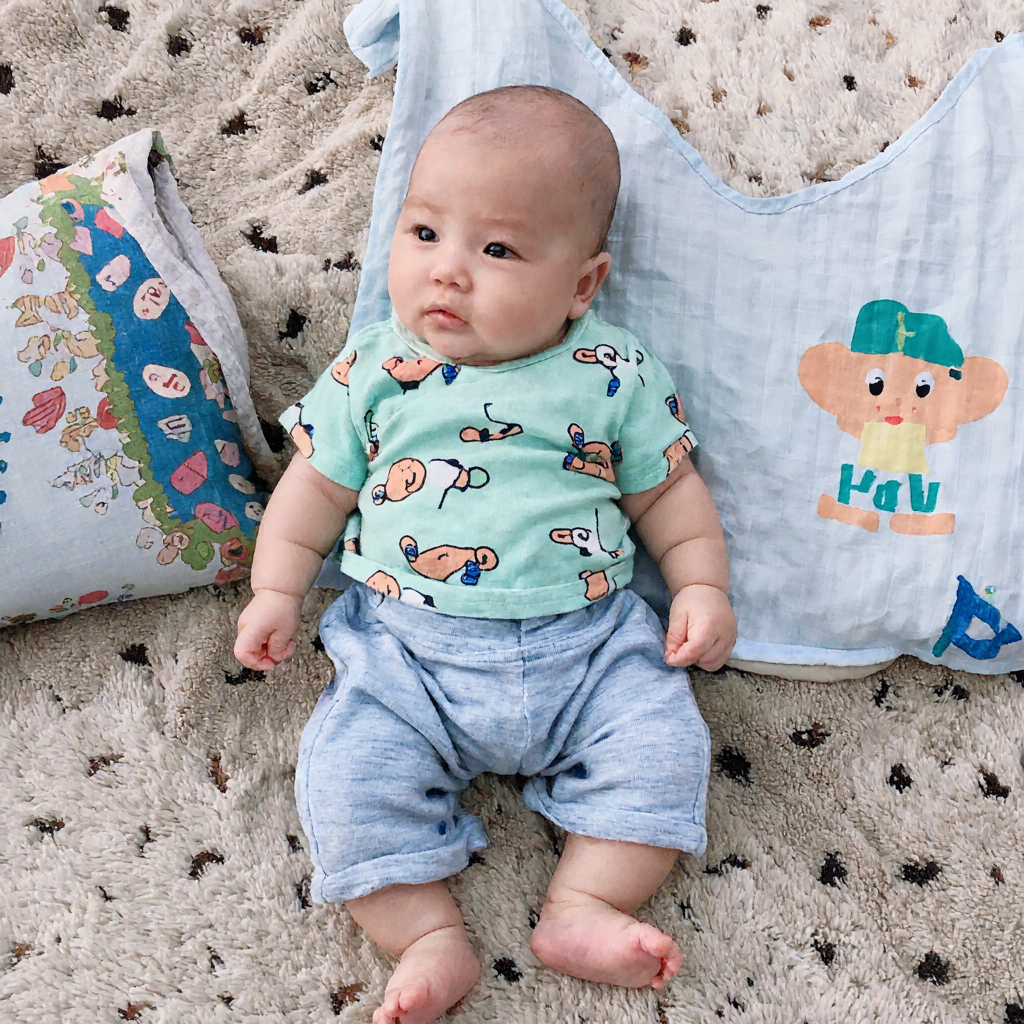

In [ ]:
# 6. 文生图测试（6 步蒸馏、无 CFG；不支持 negative prompt；需要详细的英文描述）
import base64, io, time, requests
from PIL import Image
from IPython.display import display

API_KEY = open('/content/api_key.txt').read().strip()

prompt = ('十个月大的婴幼儿')
size = '2048x2048'      # 大图可用 4096x4096 / 5472x3072 等
seed = 42               # 换数字 = 换一张不同的图
out_file = '/content/out.png'

t = time.time()
r = requests.post('http://localhost:8000/v1/images/generations', timeout=1800,
                  headers={'Authorization': f'Bearer {API_KEY}'},
                  json={'model': 'MiniMaxAI/MiniMax-H3-Image', 'prompt': prompt,
                        'size': size, 'n': 1, 'seed': seed, 'response_format': 'b64_json'})
print(r.status_code, f'{time.time()-t:.1f}s')
if not r.ok:
    print(r.text[:2000])
else:
    img = Image.open(io.BytesIO(base64.b64decode(r.json()['data'][0]['b64_json'])))
    img.save(out_file); print(img.size, '已保存到', out_file)
    display(img.resize((1024, img.height * 1024 // img.width)))

In [ ]:
# 5b. 默认尺寸代理：未指定 size 时用 2048x2048（端口 8001 → 8000）
import threading, httpx, uvicorn, json, time
from fastapi import FastAPI, Request, Response

DEFAULT_SIZE = '2048x2048'
app = FastAPI()
client = httpx.AsyncClient(base_url='http://localhost:8000', timeout=1800)

@app.api_route('/{path:path}', methods=['GET', 'POST'])
async def proxy(path: str, req: Request):
    body = await req.body()
    headers = {k: v for k, v in req.headers.items() if k.lower() not in ('host', 'content-length')}
    if path.endswith('images/generations') and body:
        data = json.loads(body)
        if not data.get('size'):
            data['size'] = DEFAULT_SIZE
        body = json.dumps(data).encode()
    r = await client.request(req.method, '/' + path, params=req.query_params, content=body, headers=headers)
    return Response(r.content, status_code=r.status_code,
                    headers={k: v for k, v in r.headers.items() if k.lower() not in ('content-length', 'content-encoding', 'transfer-encoding')})

srv = uvicorn.Server(uvicorn.Config(app, host='0.0.0.0', port=8001, log_level='warning'))
threading.Thread(target=srv.run, daemon=True).start()
time.sleep(3)
print('代理已启动：http://localhost:8001，默认尺寸', DEFAULT_SIZE)

代理已启动：http://localhost:8001，默认尺寸 2048x2048


In [ ]:
# 7b. 反向隧道到德国 VPS（替代 Cloudflare，断线自动重连）
import os, subprocess, base64, time
from google.colab import userdata
os.makedirs('/root/.ssh', exist_ok=True)
open('/root/.ssh/vps_tunnel', 'wb').write(base64.b64decode(userdata.get('VPS_TUNNEL_KEY').strip()))
os.chmod('/root/.ssh/vps_tunnel', 0o600)
loop = '''while true; do
ssh -i /root/.ssh/vps_tunnel -o StrictHostKeyChecking=accept-new -o ServerAliveInterval=15 \
    -o ServerAliveCountMax=3 -o ExitOnForwardFailure=yes -N \
    -R 172.17.0.1:18001:127.0.0.1:8001 colabtunnel@5.175.220.237
echo "$(date) 隧道断开，5 秒后重连"; sleep 5; done'''
subprocess.Popen(['bash', '-c', loop], stdout=open('/content/vps_tunnel.log', 'w'),
                 stderr=subprocess.STDOUT, start_new_session=True)
time.sleep(8)
print(open('/content/vps_tunnel.log').read() or '✅ 隧道已连接（日志为空就是正常）')

In [ ]:
# 7. 启动公网隧道（Cloudflare 临时隧道，免注册）
import subprocess, re, time, os
if not os.path.exists('/content/cloudflared'):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared
tunnel = subprocess.Popen(['/content/cloudflared', 'tunnel', '--url', 'http://localhost:8000'],
                          stdout=open('/content/tunnel.log', 'w'), stderr=subprocess.STDOUT)
PUBLIC_URL = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', open('/content/tunnel.log').read())
    if m:
        PUBLIC_URL = m.group(); break
print('公网地址：', PUBLIC_URL or '未获取到，查看 !tail /content/tunnel.log')

公网地址： https://copyrighted-infant-celebrate-coordinated.trycloudflare.com


In [ ]:
time.sleep(10)   # 新隧道需要几秒生效
r = requests.get(f'{PUBLIC_URL}/v1/models', headers={'Authorization': f'Bearer {API_KEY}'}, timeout=30)
print(r.status_code, r.text[:300])

In [ ]:
import requests
API_KEY = open('/content/api_key.txt').read().strip()
for name, port in [('服务（第5格）', 8000), ('代理（5b）', 8001)]:
    try:
        r = requests.get(f'http://localhost:{port}/v1/models', headers={'Authorization': f'Bearer {API_KEY}'}, timeout=5)
        print(f'{name} 端口{port}: ✅ 正常 ({r.status_code})')
    except Exception as e:
        print(f'{name} 端口{port}: ❌ 没在运行')

服务（第5格） 端口8000: ✅ 正常 (200)
代理（5b） 端口8001: ✅ 正常 (200)


In [ ]:
# 排错：查看服务日志 / 显存
!tail -40 /content/vllm.log
!nvidia-smi --query-gpu=memory.used,memory.total --format=csv

### 常见问题
- **磁盘不够**：Colab 本地盘放不下 ~127GB 时，可以把 `HF_HOME` 指向挂载的 Google Drive（需要 2TB 套餐，加载会慢很多）。
- **OOM**：把第 5 格换成 DLO 模式（dit+text_encoder），或先用更小的 `size`。
- **第 6 格返回 404/422**：vLLM-Omni 的图像接口路径或参数名可能与这里不同，看 `/content/vllm.log` 启动时打印的路由，或查 vllm-omni 仓库 `examples/`。
- **许可**：MiniMax-H3-Image Community License；商用等情形按许可第 IV 节需向 MiniMax 单独申请授权。